In [1]:
from typing import TypedDict
class State(TypedDict):
    good_findings: bool
    research_topics: list[str]

In [3]:
def planner_node(state: State) -> dict:
    ...

def researcher_node(state: State) -> dict:
    ...

def writer_node(state: State) -> dict:
    ...

def critique_node(state: State) -> dict: # encontrou coisas relevantes
    ...

def judge_node(state: State) -> dict: #diretrizes
    ...

def summarizer_node(state: State) -> dict:
    ...

def direct_node(state: State) -> dict:
    ...

def ask_user_node(state: State) -> dict:
    ...

In [11]:
from langgraph.graph import StateGraph, END
workflow = StateGraph(State)

workflow.add_node("planner", planner_node)
workflow.add_node("researcher", researcher_node)
workflow.add_node("critique", critique_node)
workflow.add_node("writer", writer_node)
workflow.add_node("judge", judge_node)
workflow.add_node("summarizer", summarizer_node)
workflow.add_node("direct_responce", direct_node)

workflow.set_entry_point("planner")

workflow.add_edge("researcher", "critique")
workflow.add_edge("writer", "judge")
workflow.add_edge("summarizer", END)
workflow.add_edge("direct_responce", END)

workflow.add_conditional_edges(
    "planner",
    lambda state: state["next_step"],
    {
        "direct": "direct_responce",
        "researcher": "researcher",
        "END": END
    }
)

workflow.add_conditional_edges(
    "critique",
    lambda state: state["good_findings"],
    {
        "good_findings": "writer",
        "bad_findings": "planner"
    }
)

workflow.add_conditional_edges(
    "judge",
    lambda state: state["judge_command"],
    {
        "bad_writing": "writer",
        "all_good": "summarizer"
    }
)




app = workflow.compile()

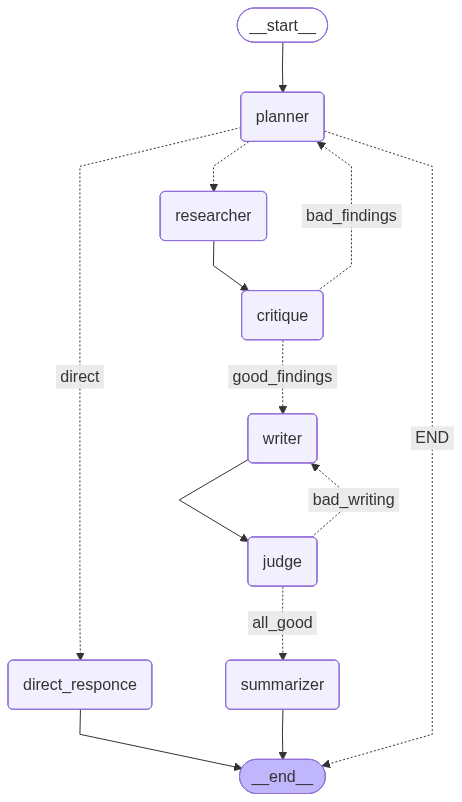

In [12]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [4]:
from langgraph.graph import StateGraph, END
workflow = StateGraph(State)

workflow.add_node("planner", planner_node)
workflow.add_node("researcher", researcher_node)
workflow.add_node("critique", critique_node)
workflow.add_node("writer", writer_node)
workflow.add_node("judge", judge_node)
workflow.add_node("summarizer", summarizer_node)
workflow.add_node("direct_responce", direct_node)

workflow.set_entry_point("planner")

workflow.add_edge("researcher", "critique")
workflow.add_edge("critique", "planner")
workflow.add_edge("writer", "judge")
workflow.add_edge("judge", "planner")
workflow.add_edge("summarizer", END)
workflow.add_edge("direct_responce", END)

workflow.add_conditional_edges(
    "planner",
    lambda state: state["next_step"],
    {
        "direct": "direct_responce",
        "researcher": "researcher",
        "writer": "writer",
        "summarizer": "summarizer",
        "END": END
    }
)

app = workflow.compile()

Uso da arquitetura star ao invés de DAG por simplificação:  
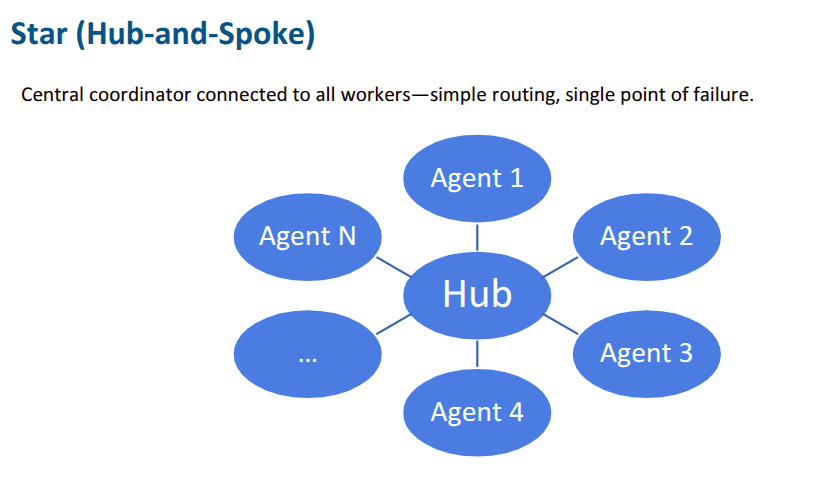  
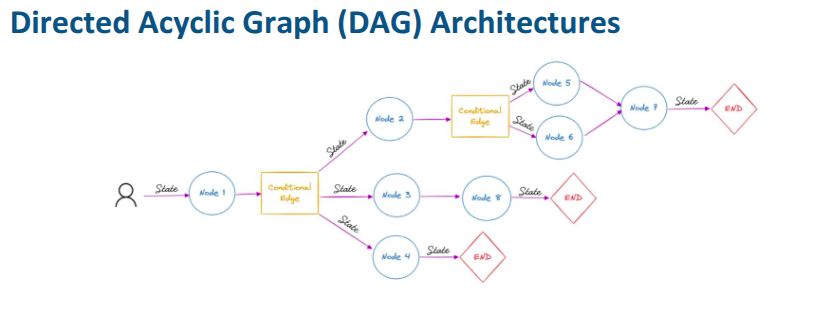

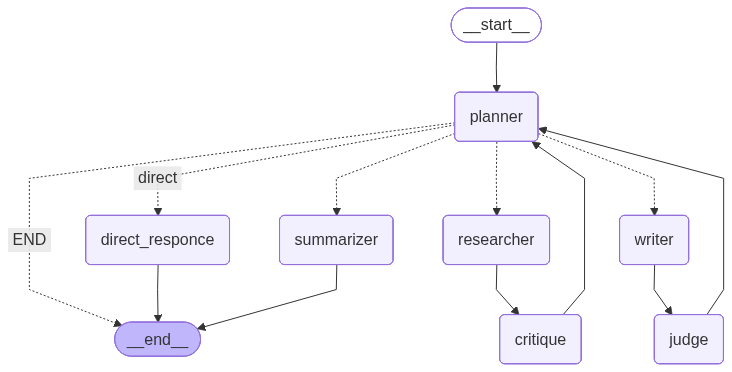

In [5]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [4]:
from langgraph.graph import StateGraph, END
workflow = StateGraph(State)

workflow.add_node("planner", planner_node)
workflow.add_node("researcher", researcher_node)
workflow.add_node("critique", critique_node)
workflow.add_node("writer", writer_node)
workflow.add_node("judge", judge_node)
workflow.add_node("summarizer", summarizer_node)
workflow.add_node("direct_responce", direct_node)
workflow.add_node("ask_user", ask_user_node)

workflow.set_entry_point("planner")

workflow.add_edge("researcher", "critique")
workflow.add_edge("critique", "planner")
workflow.add_edge("writer", "judge")
workflow.add_edge("judge", "planner")
workflow.add_edge("ask_user", "planner")
workflow.add_edge("summarizer", END)
workflow.add_edge("direct_responce", END)

from langgraph.types import Send
def route_planner(state: State):
    next_step = state["next_step"]
    if next_step == "researcher":
        return [Send("researcher", {"research_topic": topic}) for topic in state["research_topics"]]
    
    # Para os outros caminhos, o comportamento segue normal
    return next_step

workflow.add_conditional_edges(
    "planner",
    lambda state: state["next_step"] if state["next_step"]!="researcher" else [Send("researcher", {"research_topic": topic}) for topic in state["research_topics"]],
    {
        "direct": "direct_responce",
        "researcher": "researcher",
        "writer": "writer",
        "summarizer": "summarizer",
        "ask_user": "ask_user",
        "END": END
    }
)

app = workflow.compile()

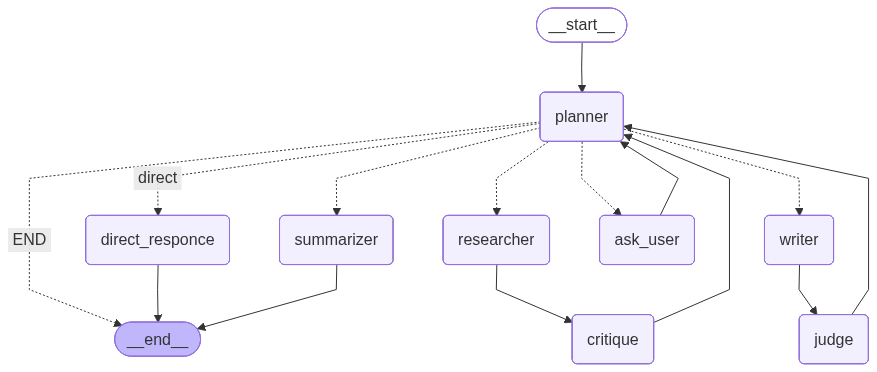

In [5]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

definir número máximo de researchers por seção (uma seção termina a cada vez que chegamos em _end_, a conversa e o histórico da conversa devem se manter na memória)  
definir número máximo de ask_user por seção 